# Mouse Dataset — Unsupervised Anomaly Detection

**Machine Learning Portfolio Project | Python · Scikit-learn · Pandas · Matplotlib**

## Project Overview

This notebook benchmarks **Isolation Forest** and **Local Outlier Factor (LOF)** on the two-dimensional Mouse dataset. It explores anomaly scores, decision thresholds, score-based clustering, and novelty detection, followed by a robustness experiment with synthetic training-set contamination.

**Dataset:** 500 observations, 2 numerical features (`x`, `y`), and 10 designated anomalies (2%). The final 10 rows provide the ground-truth anomaly labels.

**Objectives**
- Compare unsupervised anomaly detection methods and thresholding strategies.
- Evaluate both hard predictions and continuous anomaly rankings.
- Distinguish in-sample outlier detection from held-out novelty detection.
- Study the effect of contaminated training data on anomaly ranking.

**Conventions:** `0 = normal`, `1 = anomaly`, and **higher anomaly score = more anomalous**.

> **Evaluation caveat:** Most outlier-detection results are measured on the same observations used for fitting. They are descriptive, **not estimates of generalization to new data**. The separate novelty-detection experiment evaluates an unseen test set.

## Setup and Reproducibility

Configure project paths, import the required libraries and reusable functions from `src/utils.py`, set a fixed random seed (`42`), and display core library versions. The notebook can run from either the repository root or the `notebooks/` directory.

In [1]:
from pathlib import Path
import sys
import random
import importlib

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import scipy

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# Locate the repository root from either the root or notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "utils.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "utils.py").is_file() or not (PROJECT_ROOT / "data").is_dir():
    raise FileNotFoundError("Project structure not found: src/ and data/ are required.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import utils
importlib.reload(utils)

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)

NumPy: 2.3.4
Pandas: 2.3.3
Matplotlib: 3.10.7
Scikit-learn: 1.9.1
SciPy: 1.16.3


## 1. Exploratory Data Analysis (EDA)

The Mouse dataset contains 500 observations described by two numerical features (`x` and `y`). We inspect the dataset, summarize its distribution, check for missing values and duplicates, and visualize the two-dimensional feature space.

In [2]:
# Load the Mouse dataset
df = pd.read_csv(
    PROJECT_ROOT / "data" / "mouse.txt",
    sep=r"\s+",
    header=None,
    names=["x", "y"]
)

print("First observations:")
display(df.head())
print(f"Dataset shape: {df.shape}")
print("\nFeature types:")
print(df.dtypes)
print("\nDescriptive statistics:")
display(df.describe().round(4))

First observations:


,x,y
0,0.456601,0.432806
1,0.611378,0.528625
2,0.450299,0.711606
3,0.639015,0.460744
4,0.628957,0.323470


Dataset shape: (500, 2)

Feature types:
x    float64
y    float64
dtype: object

Descriptive statistics:


,x,y
count,500.0000,500.0000
mean,0.5059,0.5997
std,0.1918,0.1569
min,0.0406,0.1389
25%,0.3285,0.4690
50%,0.5047,0.6295
75%,0.6814,0.7354
max,0.9160,0.8970


### 1.1 Data Quality and Visualization

Before training the models, we check for missing values and exact duplicate observations. A scatter plot provides an initial view of the spatial distribution, but visual inspection alone cannot reliably establish which observations are anomalous.

Missing values:
x    0
y    0
dtype: int64

Exact duplicate observations: 0


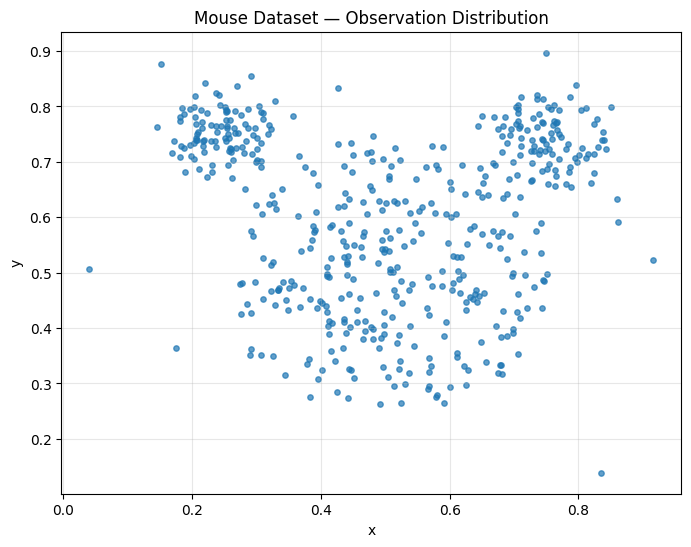

In [3]:
# Check for missing values and exact duplicates
missing, duplicates = utils.check_data_quality(df)

print("Missing values:")
print(missing)
print("\nExact duplicate observations:", duplicates)

utils.plot_data(df, title="Mouse Dataset — Observation Distribution")

**Observation:** The dataset has no missing values or exact duplicate rows. All 500 observations can be retained without additional cleaning.

### 1.2 Ground-Truth Labels and Class Imbalance

By dataset convention, the last 10 rows are anomalies (`1`); the other 490 rows are normal (`0`). We separate the two numerical features and construct labels for **evaluation**, not for training the outlier-detection models.

For the later **novelty-detection** experiment, these labels are also used to select only normal observations for the training set. This makes the two protocols different.

In [4]:
# Feature matrix
X = df[["x", "y"]].copy()

# Ground truth: 0 = normal, 1 = anomaly
y_true = utils.prepare_labels(
    n_samples=len(X),
    n_anomalies=10
)

print("Feature matrix shape:", X.shape)
print("Normal observations:", (y_true == 0).sum())
print("Anomalous observations:", (y_true == 1).sum())
print(f"Anomaly rate: {y_true.mean():.2%}")

Feature matrix shape: (500, 2)
Normal observations: 490
Anomalous observations: 10
Anomaly rate: 2.00%


**Observation:** Anomalies account for only **2%** of the dataset. Accuracy alone would be misleading; we will report precision, recall, F1-score, Average Precision (AP), and ROC-AUC.

## 2. Unsupervised Anomaly Detection

### 2.1 Isolation Forest — Model Training

Isolation Forest isolates observations through random partitions of the feature space; unusual observations often require fewer splits. We compare `contamination="auto"` and `contamination=0.02` with **100 trees** and `random_state=42`.

The models fit the full set of 500 unlabeled observations. With the same data and random seed, the contamination setting changes the **decision threshold**, rather than the underlying anomaly scores. We also record training time.

In [5]:
# Isolation Forest — automatic contamination
iso_auto = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=SEED,
    n_jobs=-1
)
iso_auto, fit_time_iso_auto = utils.fit_model(iso_auto, X)

# Isolation Forest — 2% contamination
iso_002 = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=SEED,
    n_jobs=-1
)
iso_002, fit_time_iso_002 = utils.fit_model(iso_002, X)

print(f"IF Auto — Training time: {fit_time_iso_auto:.6f} s")
print(f"IF 0.02 — Training time: {fit_time_iso_002:.6f} s")

IF Auto — Training time: 0.332102 s
IF 0.02 — Training time: 0.188392 s


### 2.2 Isolation Forest — Anomaly Scores and Predictions

We compute continuous scores and binary predictions for both configurations, using the convention **higher score = more anomalous**, `0 = normal`, and `1 = anomaly`. We also measure scoring time and count the predicted anomalies.

In [6]:
# Continuous anomaly scores and predictions
scores_iso_auto, score_time_iso_auto = utils.compute_anomaly_scores(iso_auto, X)
pred_iso_auto = utils.predict_anomalies(iso_auto, X)

scores_iso_002, score_time_iso_002 = utils.compute_anomaly_scores(iso_002, X)
pred_iso_002 = utils.predict_anomalies(iso_002, X)

for name, scores, score_time, pred in [
    ("IF Auto", scores_iso_auto, score_time_iso_auto, pred_iso_auto),
    ("IF 0.02", scores_iso_002, score_time_iso_002, pred_iso_002)
]:
    print(f"\n--- {name} ---")
    print(f"Scoring time: {score_time:.6f} s")
    print("First anomaly scores:", scores[:5])
    print("Predicted normal observations:", (pred == 0).sum())
    print("Predicted anomalies:", (pred == 1).sum())


--- IF Auto ---
Scoring time: 0.019069 s
First anomaly scores: [0.45973918 0.45538621 0.47591094 0.45873283 0.50972886]
Predicted normal observations: 375
Predicted anomalies: 125

--- IF 0.02 ---
Scoring time: 0.014987 s
First anomaly scores: [0.45973918 0.45538621 0.47591094 0.45873283 0.50972886]
Predicted normal observations: 490
Predicted anomalies: 10


### 2.3 Isolation Forest — Visualization and Threshold Analysis

For each configuration, we display (1) the distribution of anomaly scores and decision threshold, (2) detected anomalies in the original feature space, and (3) the spatial distribution of anomaly scores.

Because our scores are the negatives of scikit-learn's `score_samples`, the matching threshold is `-model.offset_`.

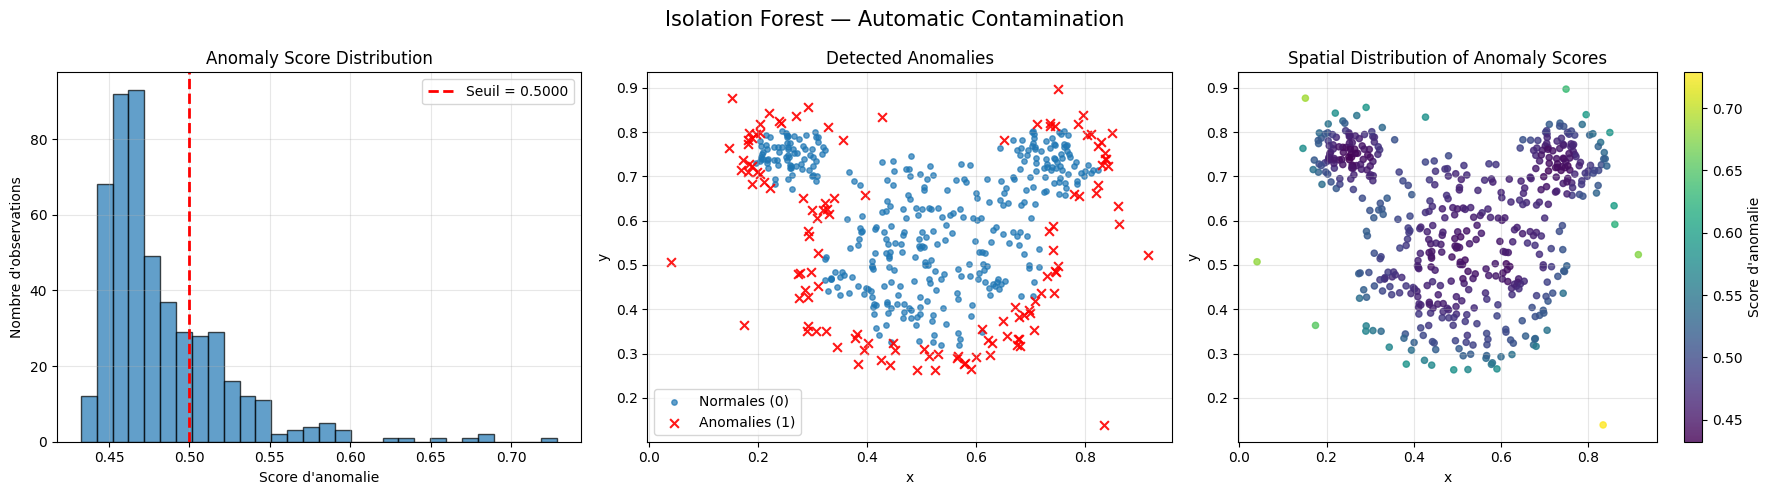

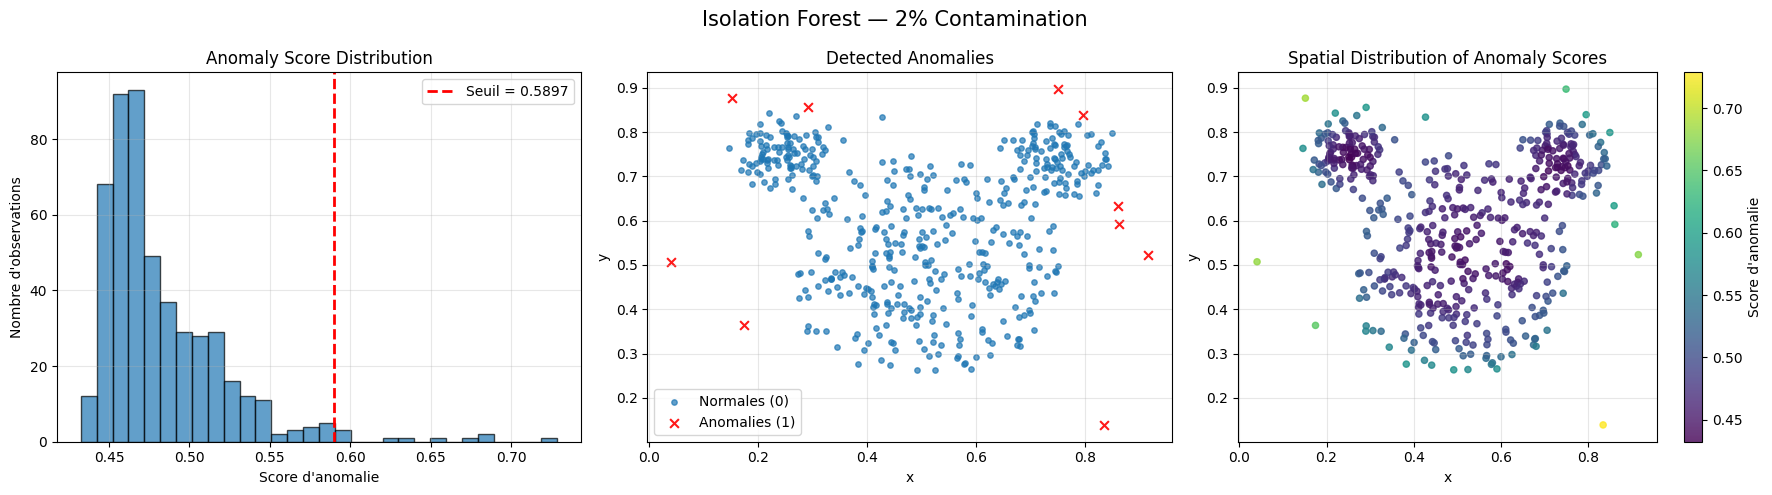

In [7]:
# Decision thresholds use the same sign convention as anomaly scores.
threshold_iso_auto = -iso_auto.offset_
threshold_iso_002 = -iso_002.offset_

for name, scores, pred, threshold in [
    ("Automatic Contamination", scores_iso_auto, pred_iso_auto, threshold_iso_auto),
    ("2% Contamination", scores_iso_002, pred_iso_002, threshold_iso_002)
]:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    utils.plot_score_distribution(
        scores, title="Anomaly Score Distribution", threshold=threshold, ax=axes[0]
    )
    utils.plot_detected_anomalies(
        X, pred, title="Detected Anomalies", ax=axes[1]
    )
    utils.plot_score_scatter(
        X, scores, title="Spatial Distribution of Anomaly Scores", ax=axes[2]
    )

    fig.suptitle(f"Isolation Forest — {name}", fontsize=15)
    plt.tight_layout()
    plt.show()

**Observation:** The two configurations yield the same continuous scores but apply different thresholds. Setting `contamination=0.02` flags roughly 2% of observations; it does **not** guarantee that all 10 real anomalies are found.

### 2.4 Local Outlier Factor (LOF) — Model Training

LOF compares the local density around each observation with densities around its neighbors. We fit `n_neighbors=20`, `novelty=False` using both `contamination="auto"` and `contamination=0.02`, and measure the fitting time.

In [8]:
# LOF — contamination auto
lof_auto = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto",
    novelty=False
)

lof_auto, fit_time_lof_auto = utils.fit_model(
    lof_auto, X
)

# LOF — contamination 0.02
lof_002 = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.02,
    novelty=False
)

lof_002, fit_time_lof_002 = utils.fit_model(
    lof_002, X
)

# Training time
print(f"LOF auto : {fit_time_lof_auto:.6f} secondes")
print(f"LOF 0.02 : {fit_time_lof_002:.6f} secondes")

LOF auto : 0.009293 secondes
LOF 0.02 : 0.007643 secondes


### 2.5 LOF — Anomaly Scores and Predictions

In outlier-detection mode (`novelty=False`), LOF computes `negative_outlier_factor_` during fitting. We invert its sign to maintain **higher score = more anomalous** and obtain the threshold as `-offset_`.

**Timing note:** LOF's neighbor calculations and training-observation scores are included in its fit time; the notebook does not report them as a separate scoring benchmark.

In [9]:
# LOF — contamination auto
scores_lof_auto = -lof_auto.negative_outlier_factor_
threshold_lof_auto = -lof_auto.offset_

pred_lof_auto = (
    scores_lof_auto > threshold_lof_auto
).astype(int)

# LOF — contamination 0.02
scores_lof_002 = -lof_002.negative_outlier_factor_
threshold_lof_002 = -lof_002.offset_

pred_lof_002 = (
    scores_lof_002 > threshold_lof_002
).astype(int)

# Display des résultats
for name, scores, threshold, pred in [
    ("LOF Auto", scores_lof_auto, threshold_lof_auto, pred_lof_auto),
    ("LOF 0.02", scores_lof_002, threshold_lof_002, pred_lof_002)
]:
    print(f"\n--- {name} ---")
    print(f"Seuil : {threshold:.6f}")
    print("First anomaly scores:", scores[:5])
    print("Predicted normal observations:", (pred == 0).sum())
    print("Predicted anomalous observations:", (pred == 1).sum())


--- LOF Auto ---
Seuil : 1.500000
First anomaly scores: [0.9802122  0.98377778 1.03751544 0.95925459 1.03803603]
Predicted normal observations: 490
Predicted anomalous observations: 10

--- LOF 0.02 ---
Seuil : 1.463024
First anomaly scores: [0.9802122  0.98377778 1.03751544 0.95925459 1.03803603]
Predicted normal observations: 490
Predicted anomalous observations: 10


### 2.6 LOF — Score Distributions and Detected Anomalies

We compare the score histograms, thresholds, binary detections, and score maps for the two LOF configurations.

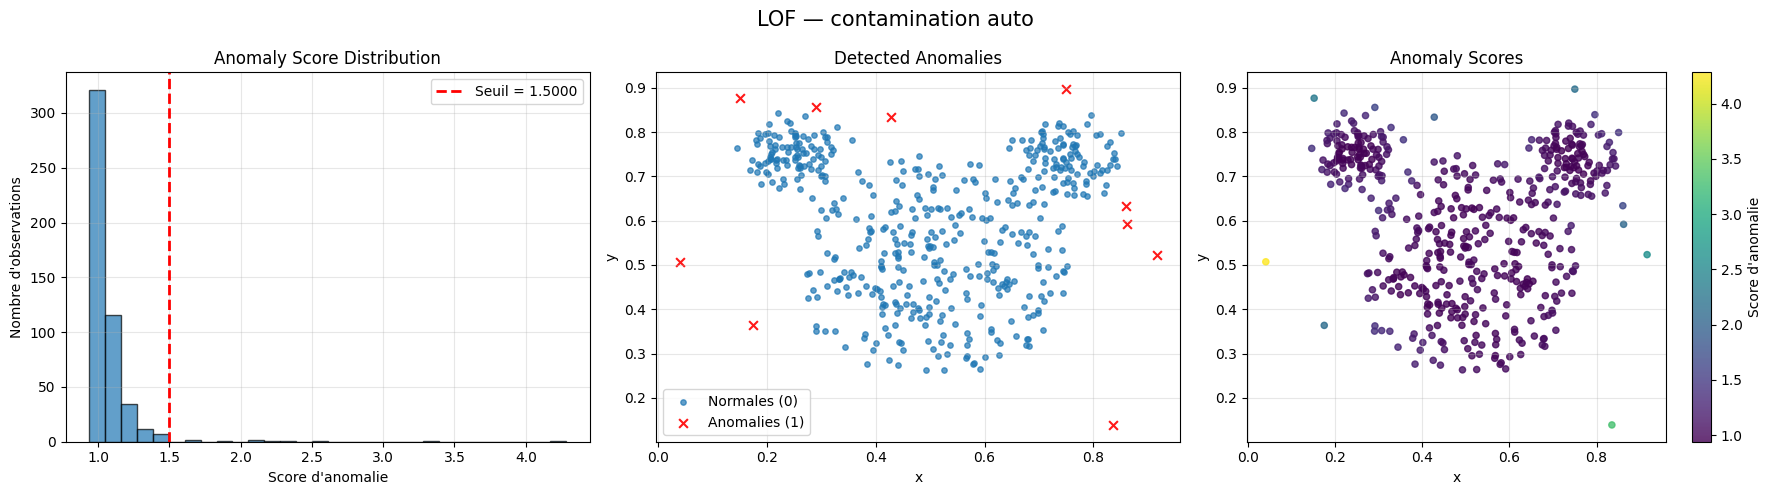

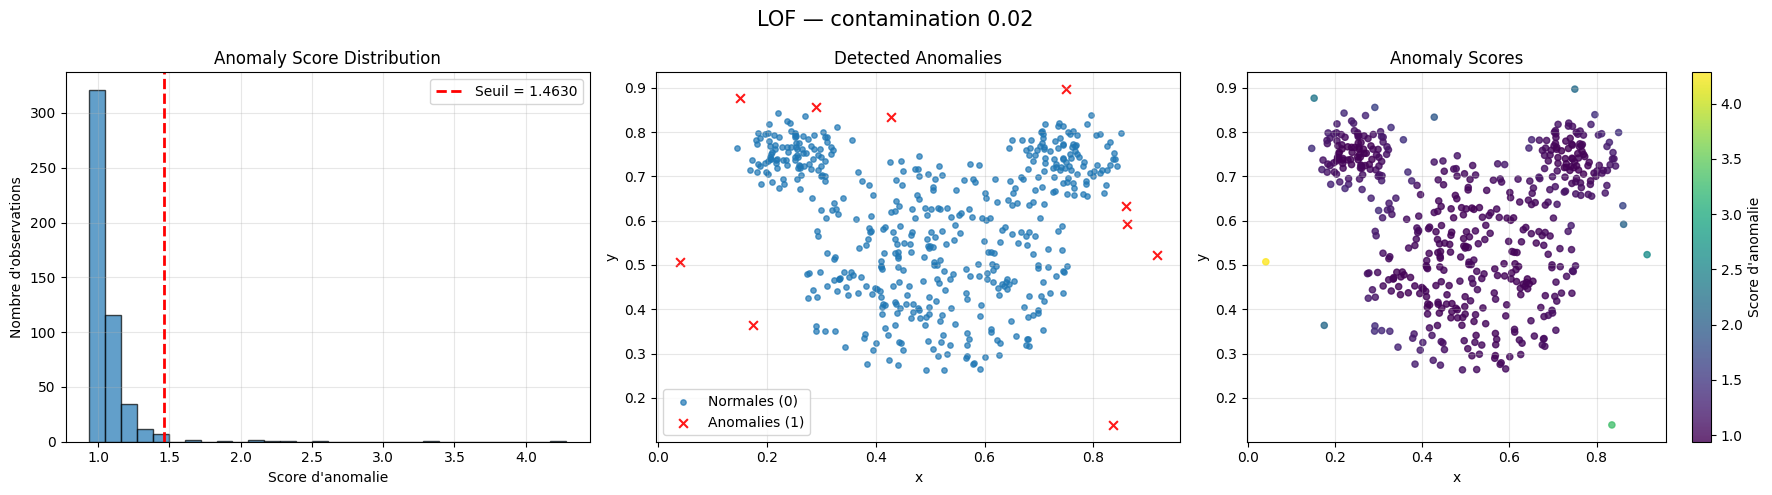

In [10]:
# Visualize both LOF configurations
for name, scores, pred, threshold in [
    ("contamination auto", scores_lof_auto, pred_lof_auto, threshold_lof_auto),
    ("contamination 0.02", scores_lof_002, pred_lof_002, threshold_lof_002)
]:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    utils.plot_score_distribution(
        scores,
        title="Anomaly Score Distribution",
        threshold=threshold,
        ax=axes[0]
    )

    utils.plot_detected_anomalies(
        X,
        pred,
        title="Detected Anomalies",
        ax=axes[1]
    )

    utils.plot_score_scatter(
        X,
        scores,
        title="Anomaly Scores",
        ax=axes[2]
    )

    fig.suptitle(
        f"LOF — {name}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

**Observation:** LOF produces the same anomaly scores for both contamination settings. Here, the decision threshold alone changes the number of flagged observations.

### 2.7 Isolation Forest vs LOF — Initial Comparison

We compare fitting time, separately measurable scoring time, decision thresholds, and the number of detections. Timing figures are environment-dependent; they should not be interpreted as a universal speed ranking.

In [11]:
# Compare models
comparaison = pd.DataFrame({
    "Modèle": [
        "IF auto",
        "IF 0.02",
        "LOF Auto",
        "LOF 0.02"
    ],

    "Temps fit (s)": [
        fit_time_iso_auto,
        fit_time_iso_002,
        fit_time_lof_auto,
        fit_time_lof_002
    ],

    "Temps scores (s)": [
        score_time_iso_auto,
        score_time_iso_002,
        np.nan,
        np.nan
    ],

    "Seuil": [
        threshold_iso_auto,
        threshold_iso_002,
        threshold_lof_auto,
        threshold_lof_002
    ],

    "Normales": [
        (pred_iso_auto == 0).sum(),
        (pred_iso_002 == 0).sum(),
        (pred_lof_auto == 0).sum(),
        (pred_lof_002 == 0).sum()
    ],

    "Anomalies": [
        (pred_iso_auto == 1).sum(),
        (pred_iso_002 == 1).sum(),
        (pred_lof_auto == 1).sum(),
        (pred_lof_002 == 1).sum()
    ]
})

# Percentage of flagged anomalies
comparaison["Anomalies (%)"] = (
    comparaison["Anomalies"] / len(X) * 100
)

display(comparaison.round(4))

,Modèle,Temps fit (s),Temps scores (s),Seuil,Normales,Anomalies,Anomalies (%)
0,IF auto,0.3321,0.0191,0.5000,375,125,25.0
1,IF 0.02,0.1884,0.0150,0.5897,490,10,2.0
2,LOF Auto,0.0093,NaN,1.5000,490,10,2.0
3,LOF 0.02,0.0076,NaN,1.4630,490,10,2.0


**Observation:** With `contamination=0.02`, both algorithms flag approximately 10 observations. The number of alerts is not a measure of correctness; we compare predictions with ground-truth labels below.

## 3. Decision Strategies and Model Evaluation

### 3.1 IQR-Based Thresholds

As a label-free alternative, we apply the interquartile range rule to continuous anomaly scores:

\[\mathrm{Threshold} = Q_3 + 1.5(Q_3-Q_1)\]

An observation is flagged when its anomaly score exceeds the threshold. Unlike contamination-based thresholding, this rule does not impose a fixed alert rate.

In [12]:
# Compute IQR thresholds
threshold_iso_iqr = utils.iqr_threshold(scores_iso_auto)
threshold_lof_iqr = utils.iqr_threshold(scores_lof_auto)

# Display thresholds
print(f"Seuil IQR — Isolation Forest : {threshold_iso_iqr:.6f}")
print(f"Seuil IQR — LOF : {threshold_lof_iqr:.6f}")

Seuil IQR — Isolation Forest : 0.562563
Seuil IQR — LOF : 1.225625


**Observation:** The IQR rule produces a threshold specific to each model's score distribution. We evaluate the resulting false positives and false negatives in Section 3.3.

### 3.2 Clustering the Anomaly Scores

We inspect the one-dimensional score distributions and apply clustering heuristics **without using ground-truth labels** to form the clusters. Their usefulness is evaluated afterward with the labels.

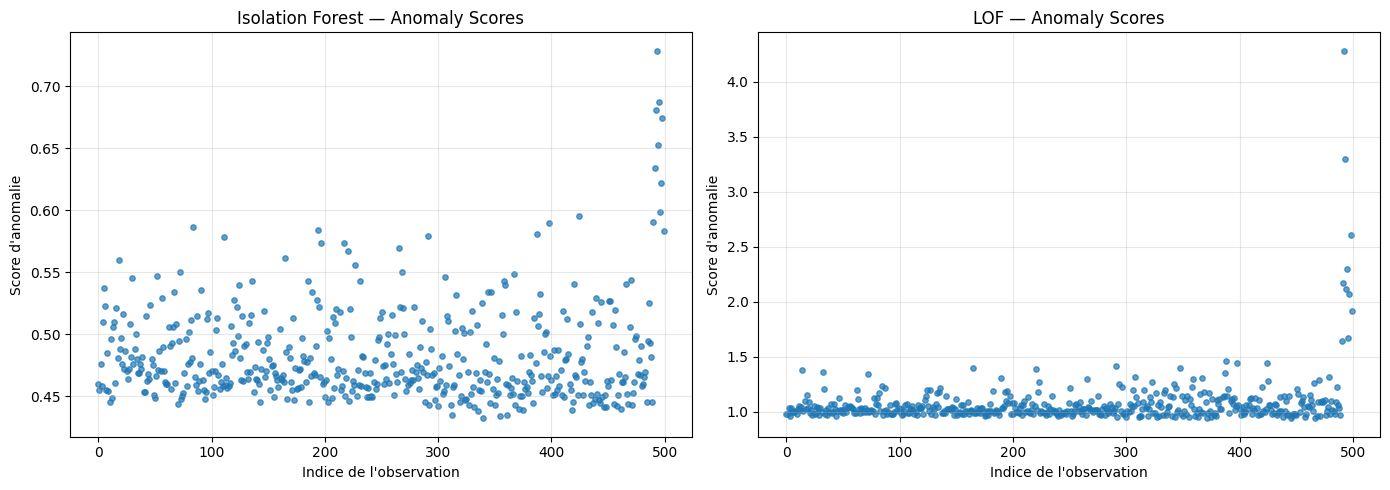

In [13]:
# Visualize anomaly scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

utils.plot_scores_points(
    scores_iso_auto,
    title="Isolation Forest — Anomaly Scores",
    ax=axes[0]
)

utils.plot_scores_points(
    scores_lof_auto,
    title="LOF — Anomaly Scores",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

**Decision rules:** For Isolation Forest scores, test **K-Means** with `k = 2, 3, 4` and flag the cluster with the highest mean score. For LOF scores, apply **DBSCAN** and flag noise points (`label = -1`). These are heuristic decision rules, not guaranteed anomaly detectors.

#### 3.2.1 Isolation Forest Scores — K-Means

We compare K-Means with `k = 2, 3, 4`. Each model is fitted once, and its predictions are stored for the later evaluation.

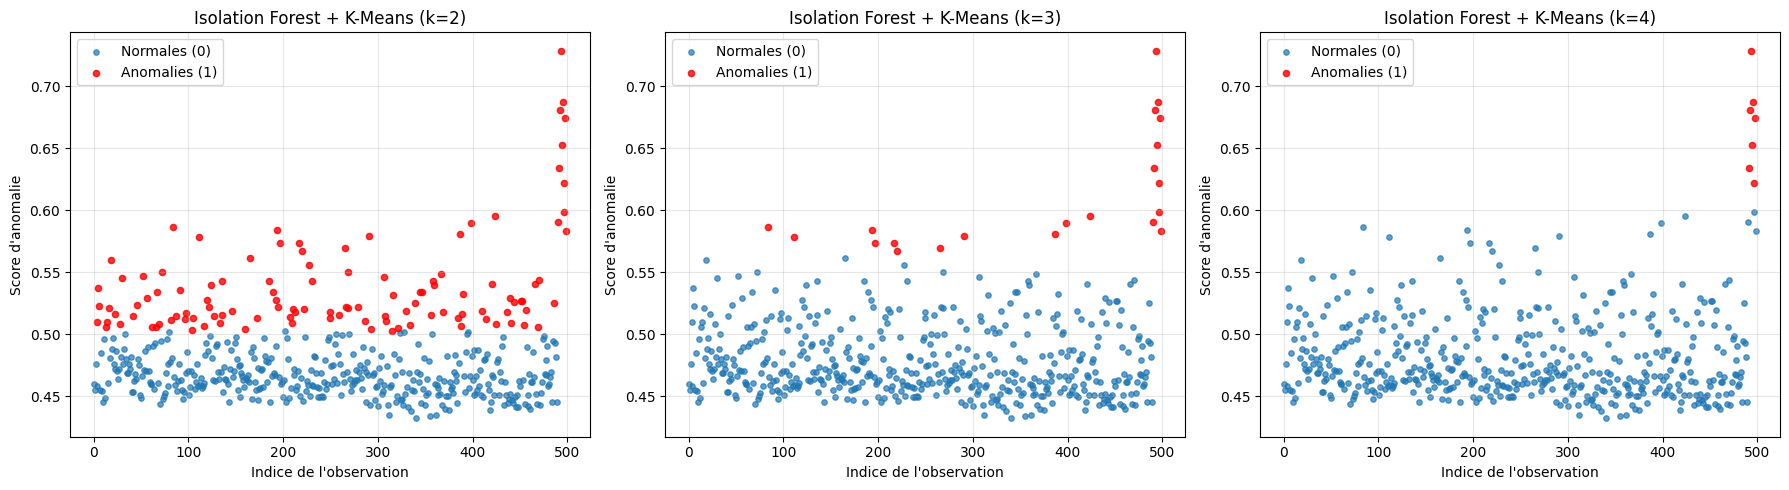

,k,Centres,Normales,Anomalies,Anomalies (%)
0,2,"[0.4662176104941591, 0.5390696813078979]",385,115,23.0
1,3,"[0.4624085206149238, 0.5142954144878888, 0.611...",479,21,4.2
2,4,"[0.4607528256702293, 0.503820565722001, 0.5567...",493,7,1.4


In [14]:
# Apply K-Means to Isolation Forest scores
resultats_kmeans_iso = {}
resultats = []

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, k in enumerate([2, 3, 4]):

    # Fit and predict
    model, pred = utils.kmeans_score_clustering(
        scores_iso_auto,
        n_clusters=k,
        random_state=SEED
    )

    # Store predictions and fitted models
    resultats_kmeans_iso[k] = {
        "model": model,
        "pred": pred
    }

    # Résumé
    resultats.append({
        "k": k,
        "Centres": np.sort(model.cluster_centers_.ravel()),
        "Normales": (pred == 0).sum(),
        "Anomalies": (pred == 1).sum(),
        "Anomalies (%)": (pred == 1).mean() * 100
    })

    # Visualization
    utils.plot_clustered_scores(
        scores_iso_auto,
        pred,
        title=f"Isolation Forest + K-Means (k={k})",
        ax=axes[i]
    )

plt.tight_layout()
plt.show()

# Comparison table
display(pd.DataFrame(resultats))

**Observation:** Changing `k` changes the proportion of observations flagged as anomalous. The cluster with the highest mean anomaly score need not correspond exactly to the true anomalies.

#### 3.2.2 LOF Scores — DBSCAN

DBSCAN is applied to the one-dimensional LOF scores using `eps=0.1` and `min_samples=5`. Observations classified as noise are treated as anomalies.

DBSCAN clusters: [-1  0]
Normal observations: 490
Anomalous observations: 10


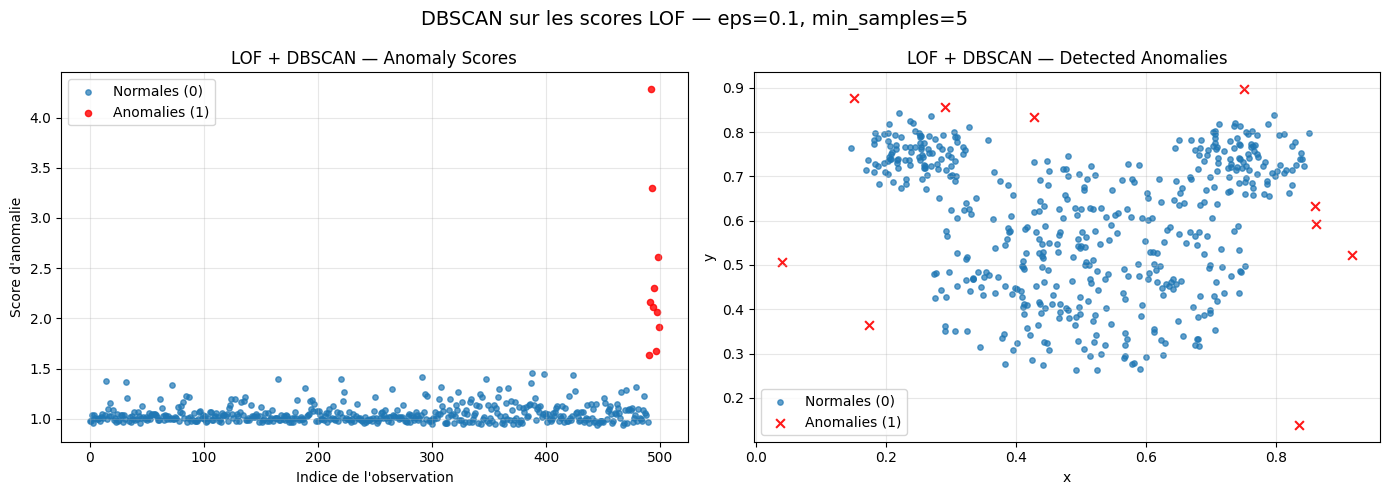

In [15]:
# Apply DBSCAN to LOF scores
dbscan_lof, pred_lof_dbscan = utils.dbscan_score_clustering(
    scores_lof_auto,
    eps=0.1,
    min_samples=5
)

# Results
print("DBSCAN clusters:", np.unique(dbscan_lof.labels_))
print("Normal observations:", (pred_lof_dbscan == 0).sum())
print("Anomalous observations:", (pred_lof_dbscan == 1).sum())

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

utils.plot_clustered_scores(
    scores_lof_auto,
    pred_lof_dbscan,
    title="LOF + DBSCAN — Anomaly Scores",
    ax=axes[0]
)

utils.plot_detected_anomalies(
    X,
    pred_lof_dbscan,
    title="LOF + DBSCAN — Detected Anomalies",
    ax=axes[1]
)

fig.suptitle(
    "DBSCAN sur les scores LOF — eps=0.1, min_samples=5",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Observation:** On the observed Mouse dataset, LOF + DBSCAN flags all 10 designated anomalies with no false positives (**F1 = 1.0**). This result is sensitive to DBSCAN's parameters and is evaluated **in-sample**, not on new observations.

### 3.3 Comparing Binary Decision Rules

#### 3.3.1 Isolation Forest-Based Rules

We compare the built-in thresholds, IQR thresholding, and K-Means score-clustering rules using confusion matrices and the anomaly-class F1-score. Ground-truth labels are used for **evaluation only**.

In [16]:
# Predictions using the IQR threshold
pred_iso_iqr = (
    scores_iso_auto > threshold_iso_iqr
).astype(int)

# Collect predictions
predictions_iso = {
    "IF auto": pred_iso_auto,
    "IF 0.02": pred_iso_002,
    "IF + IQR": pred_iso_iqr,
    "IF + K-Means k=2": resultats_kmeans_iso[2]["pred"],
    "IF + K-Means k=3": resultats_kmeans_iso[3]["pred"],
    "IF + K-Means k=4": resultats_kmeans_iso[4]["pred"]
}

# Evaluate methods
evaluations_iso = {}
resultats_iso = []

for name, pred in predictions_iso.items():

    evaluation = utils.evaluate_anomalies(y_true, pred)

    evaluations_iso[name] = evaluation

    resultats_iso.append({
        "Méthode": name,
        "Detected Anomalies": len(evaluation["Indices anomalies"]),
        "TN": evaluation["TN"],
        "FP": evaluation["FP"],
        "FN": evaluation["FN"],
        "TP": evaluation["TP"],
        "F1 anomalie": evaluation["F1"]
    })

# Comparison table
comparaison_iso = pd.DataFrame(resultats_iso)

display(comparaison_iso.round(4))

,Méthode,Detected Anomalies,TN,FP,FN,TP,F1 anomalie
0,IF auto,125,375,115,0,10,0.1481
1,IF 0.02,10,489,1,1,9,0.9000
2,IF + IQR,21,479,11,0,10,0.6452
3,IF + K-Means k=2,115,385,105,0,10,0.1600
4,IF + K-Means k=3,21,479,11,0,10,0.6452
5,IF + K-Means k=4,7,490,0,3,7,0.8235


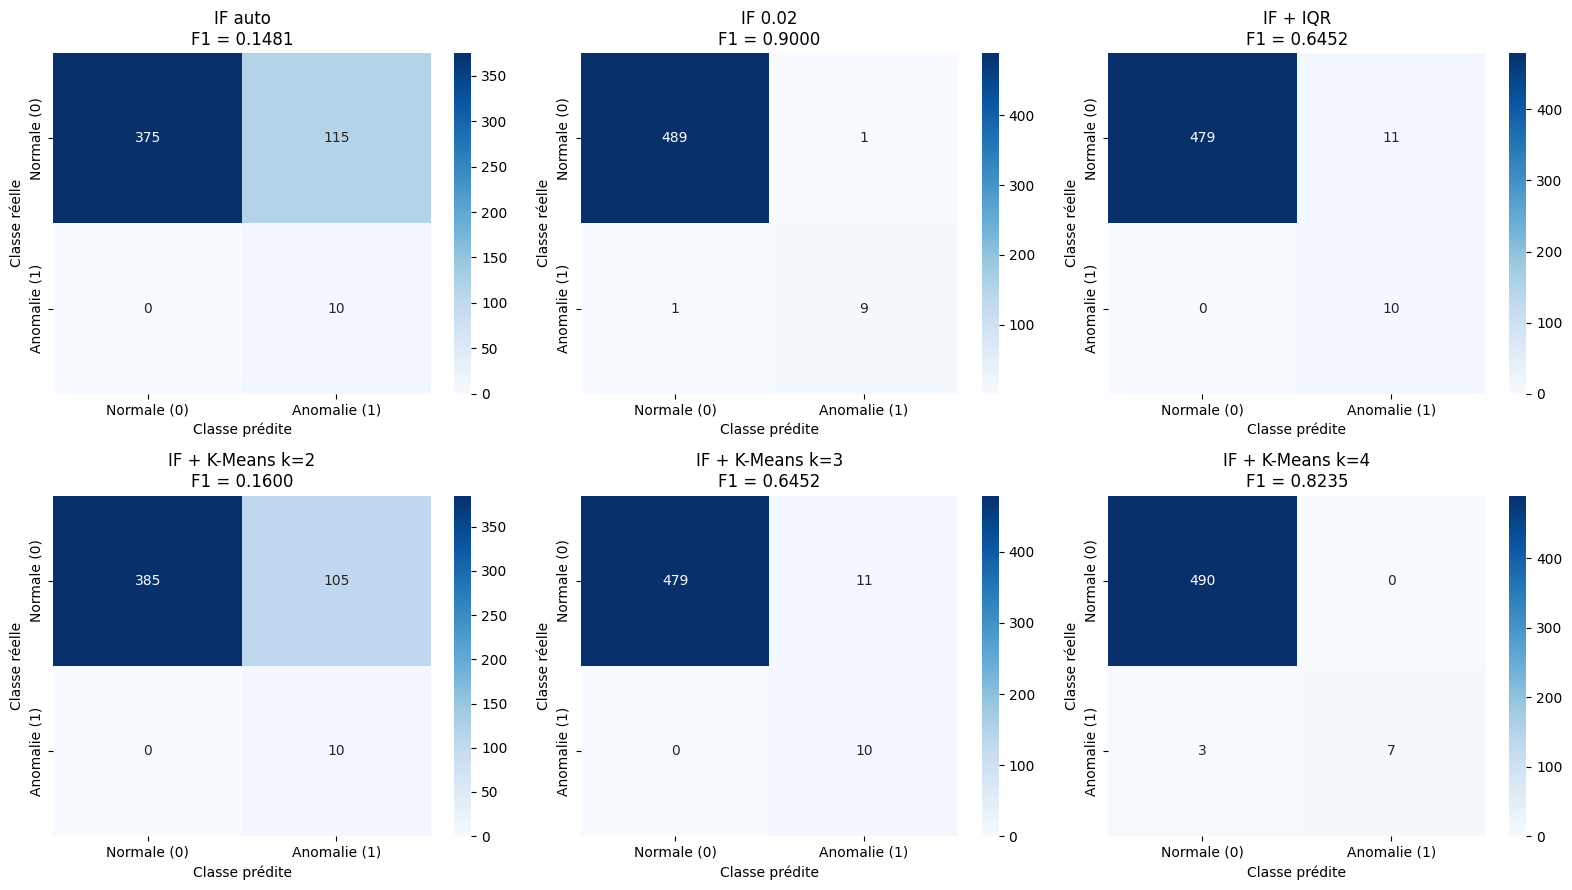

In [17]:
# Visualize confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, (name, evaluation) in zip(
    axes.flat,
    evaluations_iso.items()
):
    utils.plot_confusion_matrix(
        evaluation["Matrice"],
        title=f"{name}\nF1 = {evaluation['F1']:.4f}",
        ax=ax
    )

plt.tight_layout()
plt.show()

**Observation:** The decision rule changes the trade-off between false alerts (**FP**) and missed anomalies (**FN**). F1 summarizes precision and recall but should always be read together with the underlying confusion matrix.

#### 3.3.2 LOF-Based Rules

We evaluate LOF's automatic and 2% thresholds, the IQR rule, and the DBSCAN score-clustering rule with the same metrics.

In [18]:
# Predictions using the IQR threshold
pred_lof_iqr = (
    scores_lof_auto > threshold_lof_iqr
).astype(int)

# Collect predictions
predictions_lof = {
    "LOF Auto": pred_lof_auto,
    "LOF 0.02": pred_lof_002,
    "LOF + IQR": pred_lof_iqr,
    "LOF + DBSCAN": pred_lof_dbscan
}

# Evaluate methods
evaluations_lof = {}
resultats_lof = []

for name, pred in predictions_lof.items():

    evaluation = utils.evaluate_anomalies(y_true, pred)

    evaluations_lof[name] = evaluation

    resultats_lof.append({
        "Méthode": name,
        "Detected Anomalies": len(evaluation["Indices anomalies"]),
        "TN": evaluation["TN"],
        "FP": evaluation["FP"],
        "FN": evaluation["FN"],
        "TP": evaluation["TP"],
        "F1 anomalie": evaluation["F1"]
    })

# Comparison table
comparaison_lof = pd.DataFrame(resultats_lof)

display(comparaison_lof.round(4))

,Méthode,Detected Anomalies,TN,FP,FN,TP,F1 anomalie
0,LOF Auto,10,490,0,0,10,1.0000
1,LOF 0.02,10,490,0,0,10,1.0000
2,LOF + IQR,37,463,27,0,10,0.4255
3,LOF + DBSCAN,10,490,0,0,10,1.0000


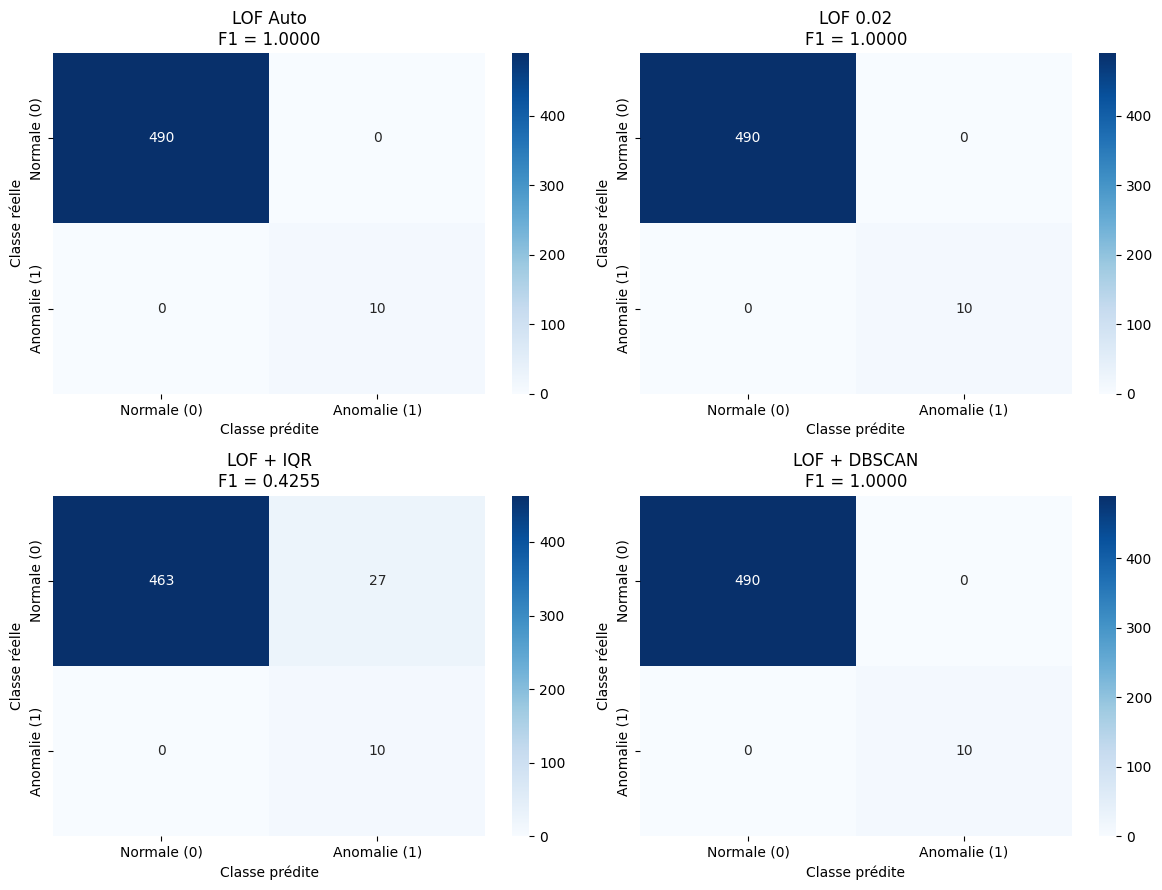

In [19]:
# Visualize confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, evaluation) in zip(
    axes.flat,
    evaluations_lof.items()
):
    utils.plot_confusion_matrix(
        evaluation["Matrice"],
        title=f"{name}\nF1 = {evaluation['F1']:.4f}",
        ax=ax
    )

plt.tight_layout()
plt.show()

**Observation:** LOF Auto, LOF 0.02, and LOF + DBSCAN each detect the 10 anomalies with no false positives (**F1 = 1.0**). LOF + IQR finds all 10 anomalies but adds 27 false positives (**F1 ≈ 0.426**).

These are results on the **observed fitting dataset** and should not be interpreted as a guarantee of future performance.

#### 3.3.3 Overall Comparison

We combine the Isolation Forest and LOF results, then sort by anomaly-class F1-score to compare the decision rules on this dataset.

In [20]:
# Combine Isolation Forest and LOF evaluations
comparaison_globale = pd.concat(
    [comparaison_iso, comparaison_lof],
    ignore_index=True
)

# Sort methods by decreasing F1
comparaison_globale = comparaison_globale.sort_values(
    "F1 anomalie",
    ascending=False
).reset_index(drop=True)

display(comparaison_globale.round(4))

,Méthode,Detected Anomalies,TN,FP,FN,TP,F1 anomalie
0,LOF + DBSCAN,10,490,0,0,10,1.0000
1,LOF 0.02,10,490,0,0,10,1.0000
2,LOF Auto,10,490,0,0,10,1.0000
3,IF 0.02,10,489,1,1,9,0.9000
4,IF + K-Means k=4,7,490,0,3,7,0.8235
5,IF + IQR,21,479,11,0,10,0.6452
6,IF + K-Means k=3,21,479,11,0,10,0.6452
7,LOF + IQR,37,463,27,0,10,0.4255
8,IF + K-Means k=2,115,385,105,0,10,0.1600
9,IF auto,125,375,115,0,10,0.1481


**Key findings:**
- **LOF Auto, LOF 0.02, LOF + DBSCAN:** F1 = 1.00 (10 TP, 0 FP, 0 FN).
- **Isolation Forest 0.02:** F1 = 0.90 (9 TP, 1 FP, 1 FN).
- **Isolation Forest + IQR:** all 10 anomalies found but 11 false positives (F1 ≈ 0.645).

LOF performs better than Isolation Forest **on this specific dataset**. The algorithms rank observations differently: Isolation Forest emphasizes ease of isolation, whereas LOF emphasizes relative local density. The 10-anomaly sample is small, and these in-sample metrics do not establish generalization.

#### 3.3.4 Disagreement Analysis — Isolation Forest vs LOF

We compare which observations are flagged by the two 2%-contamination configurations, including detections shared by both methods and detections unique to one method.

In [21]:
# Compare anomalies detected by IF and LOF
indices_if = set(np.where(pred_iso_002 == 1)[0])
indices_lof = set(np.where(pred_lof_002 == 1)[0])

communs = indices_if & indices_lof
uniquement_if = indices_if - indices_lof
uniquement_lof = indices_lof - indices_if

print("Common detections:", len(communs))
print("Isolation Forest only:", len(uniquement_if))
print("LOF only:", len(uniquement_lof))

print("\nIndices uniquement IF :", sorted(uniquement_if))
print("Only LOF indices:", sorted(uniquement_lof))

Common detections: 9
Isolation Forest only: 1
LOF only: 1

Indices uniquement IF : [np.int64(424)]
Only LOF indices: [np.int64(499)]


**Observation:** The two models agree on 9 flagged observations but disagree on two:
- **Index 424:** flagged only by Isolation Forest; it is a false positive.
- **Index 499:** flagged only by LOF; it is a true anomaly missed by Isolation Forest.

Thus LOF detects all 10 anomalies without false positives, while Isolation Forest misses one anomaly and raises one false alarm under this threshold.

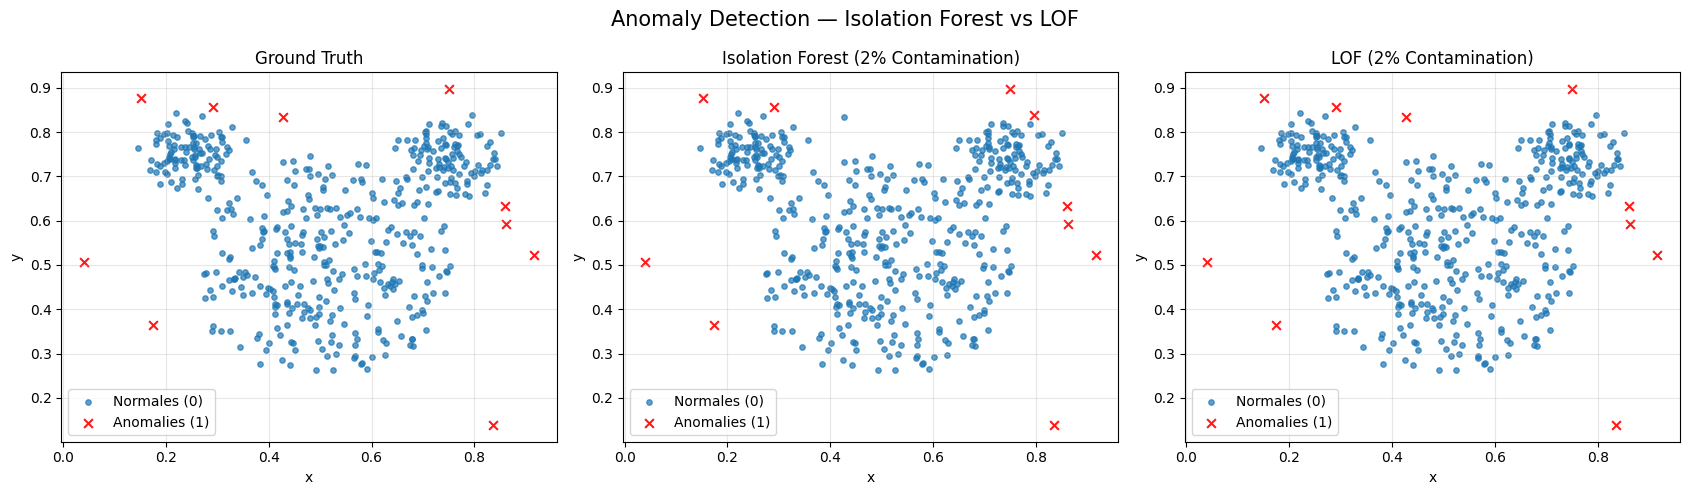

In [22]:

# Compare ground truth and model predictions
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

utils.plot_detected_anomalies(
    X,
    y_true,
    title="Ground Truth",
    ax=axes[0]
)

utils.plot_detected_anomalies(
    X,
    pred_iso_002,
    title="Isolation Forest (2% Contamination)",
    ax=axes[1]
)

utils.plot_detected_anomalies(
    X,
    pred_lof_002,
    title="LOF (2% Contamination)",
    ax=axes[2]
)

fig.suptitle(
    "Anomaly Detection — Isolation Forest vs LOF",
    fontsize=15
)

plt.tight_layout()

# Export figure
figure_dir = PROJECT_ROOT / "figures" / "mouse"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "detection_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



**Observation:**

- **Ground Truth:** 10 anomalous observations.
- **Isolation Forest:** Detects 9 anomalies, with 1 false positive and 1 false negative (F1 = 0.90).
- **LOF:** Correctly identifies all 10 anomalies without false positives (F1 = 1.00).

LOF performs better than Isolation Forest on this dataset. However, these results are obtained through in-sample outlier detection and do not demonstrate generalization to unseen data.


### 3.4 Threshold-Independent Ranking Metrics — AP and ROC-AUC

**Average Precision (AP)** summarizes precision-recall ranking performance and is especially informative when anomalies are rare. **ROC-AUC** measures how consistently anomalous observations receive higher scores than normal ones.

Both metrics are calculated from **continuous scores**, independently of the binary decision threshold.

In [23]:
# Continuous scores from both models
scores_models = {
    "Isolation Forest": scores_iso_auto,
    "LOF": scores_lof_auto
}

# Evaluate anomaly scores
resultats_scores = []

for name, scores in scores_models.items():

    ap, auc = utils.evaluate_scores(y_true, scores)

    resultats_scores.append({
        "Modèle": name,
        "AP": ap,
        "AUC-ROC": auc
    })

# Comparison table
comparaison_scores = pd.DataFrame(resultats_scores)

display(comparaison_scores.round(4))

,Modèle,AP,AUC-ROC
0,Isolation Forest,0.9614,0.999
1,LOF,1.0000,1.000


**Observation:** Isolation Forest achieves **AP = 0.9614** and **ROC-AUC = 0.9990**; LOF achieves **AP = 1.0000** and **ROC-AUC = 1.0000** on the observed dataset.

Changing only the threshold leaves these ranking metrics unchanged, although precision, recall, and F1 can change. These scores are **in-sample** and are not estimates of performance on unseen observations.

## 4. Novelty Detection with LOF

### 4.1 Train/Test Preparation

Unlike outlier detection, **novelty detection** learns a reference distribution from training observations and scores new observations afterward.

Using ground-truth labels, we construct a training set of **392 normal observations**. The held-out test set contains **98 normal observations and all 10 anomalies**. Training is therefore informed by labels, which makes this protocol **different from purely unsupervised outlier detection**.

Dimensions apprentissage : (392, 2)
Dimensions test : (108, 2)

Observations normales dans le test : 98
Anomalies dans le test : 10


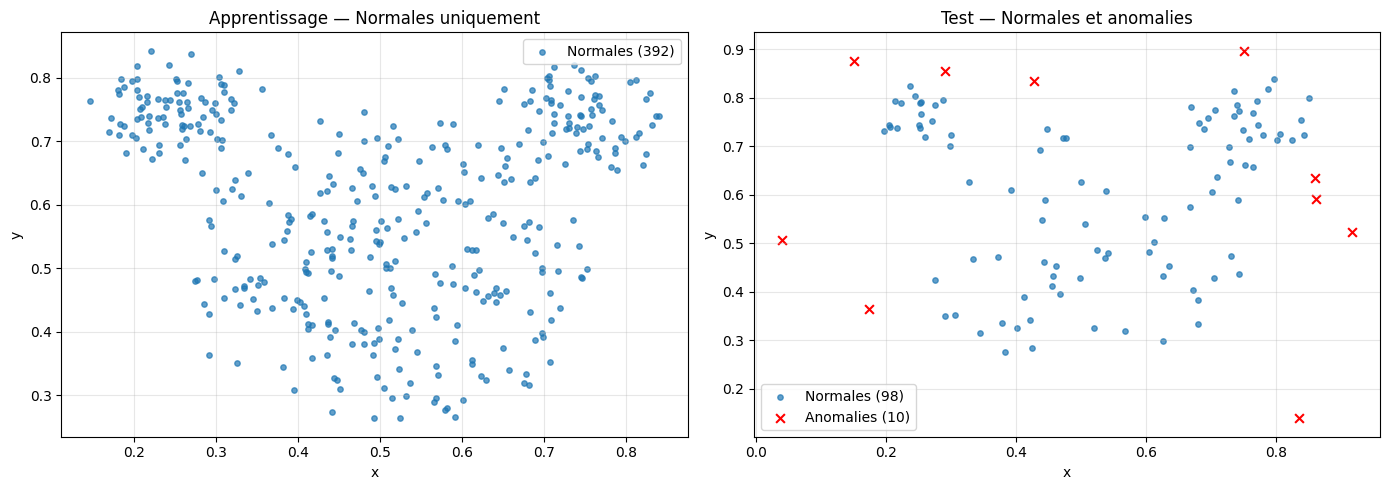

In [24]:
# Prepare data for novelty detection
X_train, X_test, y_test = utils.split_novelty_data(
    X,
    y_true,
    test_size=0.2,
    random_state=SEED
)

# Check train/test sets
print("Dimensions apprentissage :", X_train.shape)
print("Dimensions test :", X_test.shape)

print("\nObservations normales dans le test :", (y_test == 0).sum())
print("Anomalies dans le test :", (y_test == 1).sum())

# Visualize the split
utils.plot_novelty_split(
    X_train,
    X_test,
    y_test
)

**Observation:** The held-out test set contains 108 observations not used to fit LOF. The model is fitted only on normal training observations, without seeing anomalous examples during training.

### 4.2 LOF Novelty — Model Training

We fit LOF with `novelty=True`, `n_neighbors=20`, and `contamination="auto"` using only normal training observations. Training time is recorded.

In [25]:
# LOF — novelty detection
lof_novelty = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto",
    novelty=True
)

# Fit on normal observations
lof_novelty, fit_time_lof_novelty = utils.fit_model(
    lof_novelty,
    X_train.to_numpy()
)

# Training time
print(f"Training time: {fit_time_lof_novelty:.6f} s")

Training time: 0.005957 s


### 4.3 LOF Novelty — Scores and Predictions

We score and classify only the held-out test observations, applying the same anomaly-score and binary-label conventions. Separate scoring time is measured.

In [26]:
# Compute scores on the test set
scores_lof_novelty, score_time_lof_novelty = (
    utils.compute_anomaly_scores(lof_novelty, X_test.to_numpy())
)

# Predictions on the test set
pred_lof_novelty = utils.predict_anomalies(
    lof_novelty, X_test.to_numpy()
)

# Display results
print(f"Scoring time: {score_time_lof_novelty:.6f} s")

print("\nFirst scores:", scores_lof_novelty[:5])

print("\nPredicted normal observations:", (pred_lof_novelty == 0).sum())
print("Predicted anomalies:", (pred_lof_novelty == 1).sum())

Scoring time: 0.002327 s

First scores: [1.2337881  1.47339854 1.02143215 1.11196771 0.98699069]

Predicted normal observations: 94
Predicted anomalies: 14


### 4.4 LOF Novelty — Evaluation

We evaluate binary predictions with a confusion matrix and anomaly-class F1-score, and evaluate continuous anomaly scores with AP and ROC-AUC **on the held-out test set**.

In [27]:
# Evaluate predictions
evaluation_novelty = utils.evaluate_anomalies(
    y_test,
    pred_lof_novelty
)

# Confusion matrix and metrics
print("Confusion matrix:")
print(evaluation_novelty["Matrice"])

print("\nTN :", evaluation_novelty["TN"])
print("FP :", evaluation_novelty["FP"])
print("FN :", evaluation_novelty["FN"])
print("TP :", evaluation_novelty["TP"])

print(f"\nF1 anomalie : {evaluation_novelty['F1']:.4f}")

# Evaluate continuous scores
ap_novelty, auc_novelty = utils.evaluate_scores(
    y_test,
    scores_lof_novelty
)

print(f"AP : {ap_novelty:.4f}")
print(f"AUC-ROC : {auc_novelty:.4f}")

Confusion matrix:
[[94  4]
 [ 0 10]]

TN : 94
FP : 4
FN : 0
TP : 10

F1 anomalie : 0.8333
AP : 1.0000
AUC-ROC : 1.0000


**Observation:** LOF Novelty produces **TN = 94, FP = 4, FN = 0, TP = 10**, with **F1 = 0.8333**, **AP = 1.0000**, and **ROC-AUC = 1.0000**.

The scores rank the 10 anomalous test observations above normal ones, yet the default threshold still produces four false alerts. High ranking quality does **not** imply a perfectly calibrated decision threshold. The test contains only 10 anomalies.

### 4.5 LOF Novelty — Visual Comparison

We plot the ground-truth anomalies and the model's predictions side by side in the held-out test feature space to locate false positives.

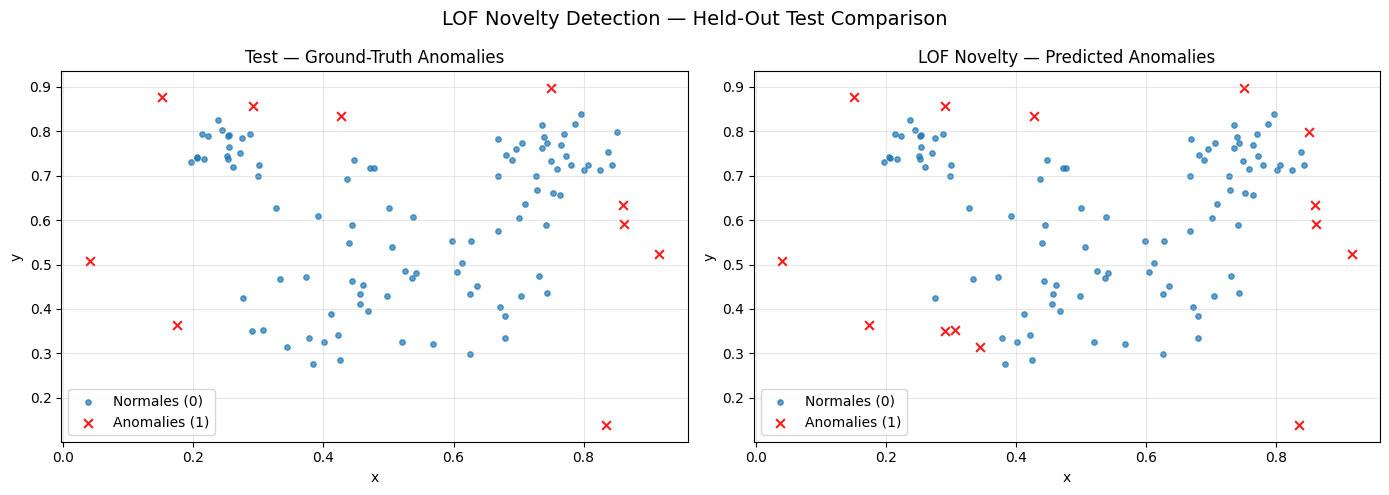

In [28]:
# Compare true vs predicted anomalies
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

utils.plot_detected_anomalies(
    X_test,
    y_test,
    title="Test — Ground-Truth Anomalies",
    ax=axes[0]
)

utils.plot_detected_anomalies(
    X_test,
    pred_lof_novelty,
    title="LOF Novelty — Predicted Anomalies",
    ax=axes[1]
)

fig.suptitle(
    "LOF Novelty Detection — Held-Out Test Comparison",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Observation:** LOF Novelty finds all 10 test anomalies and produces four false positives. This explains the perfect recall but F1 below 1.0.

### 4.6 Outlier Detection vs Novelty Detection

| Aspect | Outlier detection | Novelty detection |
|---|---|---|
| LOF setting | `novelty=False` | `novelty=True` |
| Training data | All 500 observations | 392 labeled-as-normal observations |
| Evaluation data | Same 500 fitted observations | 108 held-out observations |
| Role of labels | Evaluation only | Construct normal training set and evaluate test |

**Interpretation:** The two experiments differ in both information available at training and the evaluation protocol. Their metrics are therefore **not directly comparable**.

**Limitation:** The novelty test contains just 10 anomalies; a small number of errors can substantially change its metrics. Results depend on this dataset and the chosen split.

## 5. Robustness to Training-Set Contamination

### 5.1 Experimental Setup

We study how synthetic contamination of the normal reference set affects Isolation Forest and LOF in **novelty scoring**.

- **Training reference:** 392 normal observations from Section 4.
- **Fixed real test set:** 98 normal observations and 10 real anomalies.
- **Synthetic contamination rates:** 0%, 5%, and 10%, created by replacing normal training points.
- **Random seeds:** 42, 123, and 2026.
- **Models:** Isolation Forest (100 trees, `contamination="auto"`) and LOF (`n_neighbors=20`, `contamination="auto"`, `novelty=True`).

For each rate and seed, the training set is regenerated and the model refitted. The **same unchanged real test set** is used for all runs. We compare Average Precision and computational time. Isolation Forest's model seed stays fixed at 42 to isolate the effect of generated contamination.

In [29]:

# Experiment parameters
contamination_levels_mouse = [0.0, 0.05, 0.10]
seeds_mouse = [42, 123, 2026]

# Reuse the novelty-detection split
X_train_normal_mouse = X_train.copy()
X_test_fixed_mouse = X_test.copy()
y_test_fixed_mouse = np.asarray(y_test).copy()

# Checks
print("Training set:", X_train_normal_mouse.shape)
print("Test set:", X_test_fixed_mouse.shape)

print("Normal test observations:", (y_test_fixed_mouse == 0).sum())
print("Anomalous test observations:", (y_test_fixed_mouse == 1).sum())

print("\nTaux de contamination :", contamination_levels_mouse)
print("Random seeds:", seeds_mouse)


Training set: (392, 2)
Test set: (108, 2)
Normal test observations: 98
Anomalous test observations: 10

Taux de contamination : [0.0, 0.05, 0.1]
Random seeds: [42, 123, 2026]


**Verification:** Training data contain 392 observations, and the fixed test set contains 98 normal and 10 anomalous observations. Contamination is generated **only for training**; the test set is never altered.

### 5.2 Synthetic Anomaly Generation

`utils.contaminate_training_data()` generates candidate anomalies around the normal-data distribution, favoring low-density areas through k-nearest-neighbor distances. It replaces a randomly selected fraction of normal training points while keeping the training set at 392 rows.

For contamination rates of 0%, 5%, and 10%, the function replaces **0, 20, and 39** points respectively. These are **synthetic anomalies**, not the original Mouse anomalies.

In [30]:

# Generate contaminated training sets for visualization
datasets_contamines_mouse = {}

for taux in contamination_levels_mouse:

    X_cont = utils.contaminate_training_data(
        X_train_normal_mouse,
        contamination_rate=taux,
        random_state=SEED
    )

    datasets_contamines_mouse[taux] = X_cont

    # Number of replaced observations
    n_anomalies = round(len(X_train_normal_mouse) * taux)

    print(f"\nContamination : {taux:.0%}")
    print("Observations totales :", len(X_cont))
    print("Normales restantes :", len(X_cont) - n_anomalies)
    print("Anomalies synthétiques :", n_anomalies)

    # Check dimensions
    assert X_cont.shape == X_train_normal_mouse.shape



Contamination : 0%
Observations totales : 392
Normales restantes : 392
Anomalies synthétiques : 0

Contamination : 5%
Observations totales : 392
Normales restantes : 372
Anomalies synthétiques : 20

Contamination : 10%
Observations totales : 392
Normales restantes : 353
Anomalies synthétiques : 39


### 5.3 Visualizing the Contaminated Training Sets

We display the training distributions under 0%, 5%, and 10% contamination. Synthetic replacement points are highlighted to illustrate their spatial relationship to the normal data.

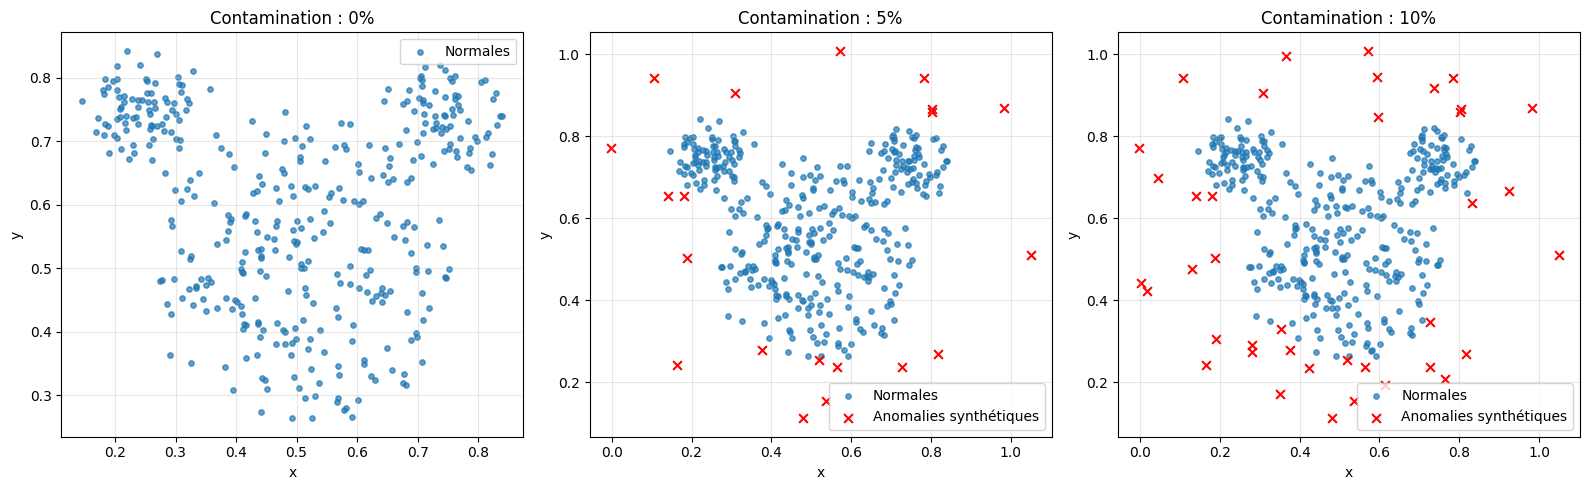

In [31]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, taux in zip(axes, contamination_levels_mouse):

    X_cont = datasets_contamines_mouse[taux]

    # Identify replaced observations
    masque_anomalies = (X_cont != X_train_normal_mouse).any(axis=1)

    normales = X_cont.loc[~masque_anomalies]
    anomalies = X_cont.loc[masque_anomalies]

    # Normal observations
    ax.scatter(
        normales["x"],
        normales["y"],
        s=15,
        alpha=0.7,
        label="Normales"
    )

    # Synthetic anomalies
    if len(anomalies) > 0:
        ax.scatter(
            anomalies["x"],
            anomalies["y"],
            color="red",
            marker="x",
            s=40,
            label="Anomalies synthétiques"
        )

    ax.set_title(f"Contamination : {taux:.0%}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Observation:** All three training sets retain 392 rows, with 0, 20, and 39 synthetic replacements. Their locations depend on the generator, which influences the robustness conclusions.

### 5.4 Retraining and Scoring Under Contamination

For each of the three contamination rates and three seeds, we fit both models with fixed hyperparameters and score the **same real test set**. This yields **18 model fits**. We record AP, fitting time, and scoring time.

Because the test set does not change, the experiment isolates variation caused by contamination of the training data, subject to the specified synthetic anomaly generator.

In [32]:

resultats_robustesse_mouse = []

for taux in contamination_levels_mouse:
    for seed in seeds_mouse:

        # Generate contaminated training data
        X_cont = utils.contaminate_training_data(
            X_train_normal_mouse,
            contamination_rate=taux,
            random_state=seed
        )

        # Models with fixed hyperparameters
        modeles_mouse = {
            "Isolation Forest": IsolationForest(
                n_estimators=100,
                contamination="auto",
                random_state=SEED,
                n_jobs=-1
            ),
            "LOF": LocalOutlierFactor(
                n_neighbors=20,
                contamination="auto",
                novelty=True
            )
        }

        for nom, modele in modeles_mouse.items():

            # Fit
            modele, temps_fit = utils.fit_model(
                modele,
                X_cont.to_numpy()
            )

            # Scores on fixed real test set
            scores, temps_score = utils.compute_anomaly_scores(
                modele,
                X_test_fixed_mouse.to_numpy()
            )

            # Average Precision
            ap, _ = utils.evaluate_scores(
                y_test_fixed_mouse,
                scores
            )

            resultats_robustesse_mouse.append({
                "Modèle": nom,
                "Contamination": taux,
                "Graine": seed,
                "AP": ap,
                "Temps fit (s)": temps_fit,
                "Temps score (s)": temps_score
            })

# Results table
df_robustesse_mouse = pd.DataFrame(
    resultats_robustesse_mouse
)

display(df_robustesse_mouse.round(4))


,Modèle,Contamination,Graine,AP,Temps fit (s),Temps score (s)
0,Isolation Forest,0.00,42,0.7944,0.1862,0.0104
1,LOF,0.00,42,1.0000,0.0021,0.0010
2,Isolation Forest,0.00,123,0.7944,0.2181,0.0129
3,LOF,0.00,123,1.0000,0.0024,0.0024
4,Isolation Forest,0.00,2026,0.7944,0.1734,0.0142
5,LOF,0.00,2026,1.0000,0.0022,0.0029
6,Isolation Forest,0.05,42,0.9102,0.1757,0.0115
7,LOF,0.05,42,1.0000,0.0031,0.0027
8,Isolation Forest,0.05,123,0.9532,0.2469,0.0239
9,LOF,0.05,123,1.0000,0.0045,0.0024


**Observation:** At 0% contamination, results are identical across the three generator seeds because the training data do not change. With 5% and 10% contamination, Isolation Forest's AP varies with the synthetic anomalies; LOF maintains AP near 1 on this test set.

### 5.5 Mean AP, Variability, and Runtime

For each model and contamination rate, we report mean AP and its standard deviation across the three generator seeds. Mean fitting and scoring times are included for context; runtime depends on the execution environment.

In [33]:

# Summarize performance by model and contamination rate
resume_robustesse_mouse = (
    df_robustesse_mouse
    .groupby(["Modèle", "Contamination"])
    .agg(
        AP_moyenne=("AP", "mean"),
        AP_ecart_type=("AP", "std"),
        Temps_fit_moyen=("Temps fit (s)", "mean"),
        Temps_score_moyen=("Temps score (s)", "mean")
    )
    .reset_index()
)

# Display
display(
    resume_robustesse_mouse.round(4)
)


,Modèle,Contamination,AP_moyenne,AP_ecart_type,Temps_fit_moyen,Temps_score_moyen
0,Isolation Forest,0.00,0.7944,0.0000,0.1926,0.0125
1,Isolation Forest,0.05,0.9178,0.0323,0.2052,0.0164
2,Isolation Forest,0.10,0.9421,0.0514,0.2053,0.0115
3,LOF,0.00,1.0000,0.0000,0.0022,0.0021
4,LOF,0.05,0.9970,0.0052,0.0033,0.0020
5,LOF,0.10,0.9936,0.0110,0.0025,0.0013


### 5.6 AP Across Contamination Levels

The plot compares mean test AP across the three contamination rates. Error bars represent the standard deviation over the three random seeds—not a confidence interval.

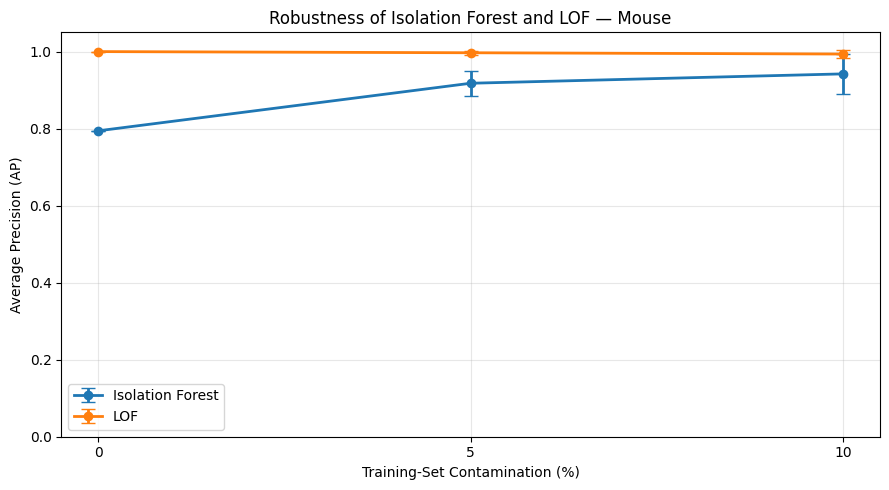

In [34]:

fig, ax = plt.subplots(figsize=(9, 5))

for nom, groupe in resume_robustesse_mouse.groupby("Modèle"):

    groupe = groupe.sort_values("Contamination")

    ax.errorbar(
        groupe["Contamination"] * 100,
        groupe["AP_moyenne"],
        yerr=groupe["AP_ecart_type"],
        marker="o",
        capsize=5,
        linewidth=2,
        label=nom
    )

ax.set_xlabel("Training-Set Contamination (%)")
ax.set_ylabel("Average Precision (AP)")
ax.set_title("Robustness of Isolation Forest and LOF — Mouse")

ax.set_xticks([0, 5, 10])
ax.set_ylim(0, 1.05)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

figure_dir = PROJECT_ROOT / "figures" / "mouse"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "robustness_analysis.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

**Observation:** Isolation Forest's mean AP rises from **0.7944** to **0.9421** between 0% and 10% synthetic contamination, while its variability also increases. LOF remains near AP = 1.0 with little variation.

This **does not** imply contamination generally improves Isolation Forest; the finding depends on the data, anomaly generator, and small held-out test set.

### 5.7 Robustness Interpretation and Limitations

**Isolation Forest:** Mean AP increases with the tested contamination levels, but variation across generated training sets also grows. In this experiment, the model's ranking is sensitive to which synthetic anomalies enter training.

**LOF:** AP stays close to 1.0 across the contamination rates and seeds tested. This suggests greater stability **within this experimental setup**, not universal robustness.

**Interpretation caveats**
- The synthetic anomaly generator favors low-density regions and determines which contaminants the models see.
- Only **three random seeds** are tested, so estimates of variability are imprecise.
- The held-out test set includes **just 10 real anomalies** and is reused in all runs.
- A single dataset and test split cannot establish cross-dataset generalization.

**Conclusion:** On this Mouse experiment, LOF's test ranking is more stable under the chosen synthetic training-set contamination, whereas Isolation Forest's AP improves on average but varies more.

## 6. Key Findings and Project Limitations

**What this experiment demonstrates**

1. **Decision thresholds matter.** Two models with identical anomaly rankings can generate very different numbers of alerts simply by changing the cutoff.
2. **LOF performs strongly on Mouse.** Multiple in-sample LOF rules achieve F1 = 1.0; Isolation Forest's 2% rule achieves F1 = 0.90. These are dataset-specific descriptive results.
3. **Ranking and classification are different.** Held-out novelty detection achieves AP and ROC-AUC of 1.0 but still raises four false-positive alerts at the default threshold.
4. **Robustness must be tested.** LOF remains stable under the selected synthetic contamination scenarios; Isolation Forest's ranking changes with the generated anomalies.

**Important limitations**
- In-sample outlier-detection metrics cannot be used as held-out generalization estimates.
- The ground-truth anomaly count is small (10), and the novelty experiment relies on labels to select normal training data.
- Robustness conclusions apply to one test split, one synthetic contamination generator, and three random seeds.
- Experimental runtimes depend on software and hardware; the notebook reports measurements, not universal speed claims.

**Next step:** Evaluate the same protocol on additional datasets or repeated held-out splits to assess broader stability and generalization.

In [35]:

output_dir = PROJECT_ROOT / "results" / "mouse"
output_dir.mkdir(parents=True, exist_ok=True)

comparaison_globale.to_csv(
    output_dir / "model_comparison.csv", index=False
)

comparaison_scores.to_csv(
    output_dir / "ranking_metrics.csv", index=False
)

resume_robustesse_mouse.to_csv(
    output_dir / "robustness_results.csv", index=False
)
